<div align="center">

# Water Sort Puzzle Solver Comparison

### Perbandingan Uniform Cost Search, Greedy Best-First Search, dan A\* Search pada Permainan Water Sort Puzzle

**Midterm Project — Artificial Intelligence**

---

| | |
|---|---|
| **Nama** | **NRP** |
| Syabil Zihni | 5025251217 |
| M. Irsyad Prihasto | 5025251185 |
| Farrel Rizqi P. | 5025251187 |
| M. Adhwa Athallah T. A. | 5025251215 |
| M. Al Fatin Rafid D. | 5025251029 |
| Daffa Rabbani G. | 5025251266 |

</div>

---

**Daftar Isi**

1. Chapter 1 — Background, Problem Statement, & Benefits
2. Chapter 2 — Method
3. Chapter 3 — Experiment & Discussion
4. Chapter 4 — Conclusion
5. References

> **Cara menjalankan:** pilih menu *Kernel → Restart & Run All*. Notebook hanya membutuhkan Python 3.8+ beserta pustaka `pandas` dan `matplotlib`. Seluruh algoritma pencarian diimplementasikan sendiri menggunakan pustaka standar (`heapq`, `itertools`, `time`).

---
# Chapter 1 — Background, Problem Statement, & Benefits

## 1.1 Latar Belakang

*Water Sort Puzzle* adalah permainan teka-teki logika yang populer pada perangkat bergerak. Pemain diberikan sejumlah tabung berisi lapisan cairan berwarna, dan tugasnya adalah memindahkan (menuangkan) cairan antartabung hingga setiap tabung hanya berisi satu warna. Meskipun aturannya sederhana, ruang kemungkinan konfigurasi tabung tumbuh sangat cepat seiring bertambahnya jumlah tabung, kapasitas, dan jumlah warna. Pemain manusia umumnya mengandalkan intuisi dan percobaan berulang (*trial and error*), yang sering kali menghasilkan langkah yang tidak efisien atau bahkan menjebak permainan pada kondisi buntu (*dead end*).

Dalam bidang Kecerdasan Buatan (*Artificial Intelligence*), permainan ini dapat dimodelkan sebagai **masalah pencarian ruang keadaan (*state-space search*)**: setiap konfigurasi tabung merupakan sebuah *state*, setiap penuangan yang sah merupakan sebuah *operator* (aksi), dan tujuan permainan dinyatakan sebagai *goal test*. Dengan pemodelan tersebut, berbagai algoritma pencarian dapat diterapkan dan dibandingkan secara objektif, baik dari sisi kualitas solusi maupun efisiensi komputasinya.

## 1.2 Rumusan Masalah (*Problem Statement*)

Berdasarkan latar belakang tersebut, rumusan masalah pada proyek ini adalah sebagai berikut.

1. Bagaimana memodelkan Water Sort Puzzle (Level 3) sebagai masalah pencarian ruang keadaan yang meliputi representasi *state*, operator, *goal test*, dan biaya langkah?
2. Bagaimana penerapan algoritma *Uniform Cost Search* (UCS), *Greedy Best-First Search*, dan *A\* Search* untuk menyelesaikan puzzle tersebut?
3. Algoritma manakah yang paling baik ditinjau dari **waktu eksekusi**, **jumlah node yang diekspansi**, dan **panjang solusi (jumlah langkah)**?

## 1.3 Tujuan

* Membangun *solver* Water Sort Puzzle yang dapat dijalankan secara otomatis dan menerima konfigurasi awal sembarang.
* Mengimplementasikan dan membandingkan tiga algoritma pencarian (UCS, Greedy Best-First, A\*) pada data Level 3.
* Menganalisis kelebihan dan kekurangan masing-masing algoritma berdasarkan hasil eksperimen kuantitatif.

## 1.4 Manfaat (*Benefits*)

* **Manfaat akademis:** menjadi contoh penerapan nyata konsep *uninformed search*, *informed search*, dan perancangan fungsi heuristik yang *admissible* pada masalah kombinatorial.
* **Manfaat praktis:** *solver* dapat dipakai untuk mencari solusi dengan jumlah langkah minimum sehingga membantu pemain yang buntu, serta dapat dimanfaatkan sebagai pembangkit petunjuk (*hint*) pada aplikasi permainan.
* **Manfaat eksperimental:** tersedianya kerangka evaluasi (waktu, node diekspansi, panjang solusi) yang dapat diperluas untuk membandingkan algoritma atau heuristik lain.

## 1.5 Batasan Masalah

* Dataset yang digunakan adalah puzzle **Water Sort Level 3** dengan kapasitas **4 blok** per tabung dan **5 tabung yang dapat dimainkan** (tabung terkunci pada gambar diabaikan).
* Setiap penuangan dihitung memiliki biaya yang sama, yaitu **1 langkah**.
* Seluruh algoritma menggunakan *graph search* dengan *closed set* agar *state* yang sama tidak diekspansi berulang kali.

---
# Chapter 2 — Method

## 2.1 Representasi *State*

Sebuah *state* direpresentasikan sebagai **tuple dari tuple**. Setiap tuple bagian dalam menyatakan satu tabung, dengan elemen diurutkan dari **dasar tabung (indeks 0) ke permukaan (elemen terakhir)**.

$$S = (T_0, T_1, \dots, T_{n-1}), \qquad T_i = (c_{i,1}, c_{i,2}, \dots, c_{i,k_i}), \quad 0 \le k_i \le C$$

dengan $n$ adalah jumlah tabung, $C$ kapasitas tabung, dan $c_{i,j}$ adalah warna blok ke-$j$ pada tabung $i$. Penggunaan tuple (immutable) membuat *state* bersifat *hashable* sehingga dapat disimpan di dalam `set` dan `dict` untuk *closed set* dan pelacakan jalur.

**Initial state (Level 3, $C = 4$, $n = 5$):**

| Tabung | Isi (dasar → atas) |
|:---:|---|
| 0 | Biru, Kuning, Merah, Merah |
| 1 | Biru, Kuning, Kuning, Kuning |
| 2 | Merah, Merah, Biru, Biru |
| 3 | *(kosong)* |
| 4 | *(kosong)* |

Masing-masing dari tiga warna (Biru, Kuning, Merah) muncul tepat 4 kali sehingga seluruh blok sebuah warna dapat memenuhi satu tabung penuh.

## 2.2 Operator / Aturan Valid

Operator `pour(i, j)` menuangkan blok pada tabung $i$ ke tabung $j$ ($i \ne j$). Operator sah apabila memenuhi seluruh prasyarat berikut.

1. Tabung sumber $T_i$ **tidak kosong**.
2. Tabung tujuan $T_j$ **tidak penuh** ($k_j < C$).
3. Tabung tujuan **kosong**, atau warna blok teratas $T_j$ **sama** dengan warna blok teratas $T_i$.

**Efek:** seluruh blok berwarna sama yang berurutan di bagian atas $T_i$ (misalkan sebanyak $m$ blok) dituangkan ke $T_j$, dibatasi oleh sisa ruang $C - k_j$. Jumlah blok yang dipindahkan adalah $\min(m,\; C - k_j)$.

**Biaya:** setiap penuangan bernilai $c(s, a, s') = 1$.

**Pemangkasan (*pruning*) langkah sia-sia:** penuangan dari tabung yang sudah seragam (hanya satu warna) ke tabung kosong tidak menghasilkan kemajuan (hanya memindahkan isi yang sama) sehingga tidak dibangkitkan. Pemangkasan ini mengurangi faktor percabangan tanpa menghilangkan solusi optimal.

## 2.3 *Goal Test*

Sebuah *state* adalah *goal* jika **setiap tabung kosong atau hanya berisi satu warna, dan tidak ada warna yang tersebar di lebih dari satu tabung**. Pada Level 3 kondisi ini ekuivalen dengan: setiap tabung yang terisi berisi 4 blok berwarna sama.

## 2.4 Algoritma Pencarian

Ketiga algoritma menggunakan kerangka *best-first search* yang sama (antrean prioritas `heapq`), dan hanya berbeda pada fungsi evaluasi $f(n)$ yang menentukan node mana yang diekspansi terlebih dahulu. Notasi: $g(n)$ adalah biaya jalur dari *initial state* ke $n$ dan $h(n)$ adalah estimasi biaya dari $n$ ke *goal*.

| Algoritma | Fungsi evaluasi $f(n)$ | Jenis | Complete | Optimal |
|---|:---:|---|:---:|:---:|
| Uniform Cost Search (UCS) | $g(n)$ | *Uninformed* | Ya | Ya |
| Greedy Best-First Search | $h(n)$ | *Informed* | Ya (pada ruang keadaan hingga dengan *closed set*) | Tidak |
| A\* Search | $g(n) + h(n)$ | *Informed* | Ya | Ya (jika $h$ *admissible* dan *consistent*) |

### a. Uniform Cost Search (UCS)
UCS selalu mengekspansi node dengan biaya jalur $g(n)$ terkecil. Karena seluruh langkah berbiaya 1, UCS berperilaku seperti *Breadth-First Search* dan **menjamin solusi dengan jumlah langkah minimum**. Kelemahannya, UCS tidak memanfaatkan informasi arah menuju *goal* sehingga cenderung mengekspansi banyak node.

### b. Greedy Best-First Search
Greedy hanya mengikuti nilai heuristik $h(n)$, yaitu selalu memilih node yang tampak paling dekat dengan *goal*. Algoritma ini biasanya sangat cepat dan hemat node, tetapi **tidak menjamin optimalitas** karena mengabaikan biaya yang telah ditempuh $g(n)$.

### c. A\* Search
A\* menggabungkan keduanya melalui $f(n) = g(n) + h(n)$. Dengan heuristik yang *admissible* dan *consistent*, A\* menjamin solusi optimal sekaligus umumnya mengekspansi node lebih sedikit daripada UCS.

## 2.5 Fungsi Heuristik $h(n)$

Heuristik yang digunakan adalah **jumlah perubahan warna (ketidakcocokan warna) pada setiap tabung**, yaitu banyaknya pasangan blok bersebelahan dalam satu tabung yang warnanya berbeda:

$$h(S) = \sum_{i=0}^{n-1} \; \sum_{j=1}^{k_i - 1} \mathbb{1}\left[\, c_{i,j} \neq c_{i,j+1} \,\right]$$

**Contoh:** tabung `[Biru, Kuning, Merah, Merah]` memiliki 2 perubahan warna (Biru→Kuning dan Kuning→Merah), sedangkan tabung `[Biru, Kuning, Kuning, Kuning]` memiliki 1 perubahan warna.

**Analisis *admissibility*.** Satu operator `pour` hanya memindahkan blok teratas yang berwarna sama ke tabung yang puncaknya berwarna sama (atau kosong). Pada tabung tujuan tidak muncul perubahan warna baru, sedangkan pada tabung sumber perubahan warna berkurang **paling banyak satu** (yaitu ketika seluruh kelompok warna teratas terangkat). Dengan demikian untuk setiap transisi $s \rightarrow s'$ berlaku $h(s) - h(s') \le 1 = c(s,s')$, yang berarti $h$ bersifat ***consistent*** (dan otomatis ***admissible***), serta $h(\text{goal}) = 0$. Akibatnya A\* dengan *closed set* menjamin solusi optimal.

## 2.6 Metrik Evaluasi

| Metrik | Penjelasan |
|---|---|
| **Waktu eksekusi (ms)** | Rata-rata waktu dinding (`time.perf_counter`) dari beberapa kali pengulangan. |
| **Node diekspansi** | Jumlah node yang dikeluarkan dari antrean prioritas dan diproses (termasuk node *goal*). |
| **Node dibangkitkan** | Jumlah *state* unik yang dimasukkan ke antrean prioritas. |
| **Panjang solusi** | Jumlah langkah penuangan pada jalur solusi. |
| **Optimal?** | Apakah panjang solusi sama dengan solusi terpendek di antara ketiga algoritma. |

## 2.7 Implementasi

Bagian berikut berisi implementasi lengkap: pustaka, representasi *state*, operator, *goal test*, heuristik, visualisasi, algoritma pencarian, dan fungsi perbandingan.

In [ ]:
# ===== Import pustaka =====
import heapq
import itertools
import time
from collections import namedtuple

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("Pustaka berhasil dimuat.")

Pustaka berhasil dimuat.


In [ ]:
# ===== State, Operator, Goal Test, dan Heuristik =====
# State  : tuple of tuple; setiap tabung disusun dari DASAR -> ATAS.

def pour(state, i, j, capacity):
    """Operator pour(i, j): tuang blok teratas tabung i ke tabung j.
    Mengembalikan (state_baru, info_langkah) atau None jika langkah tidak valid.
    info_langkah = (i, j, warna, jumlah_blok)."""
    if i == j:
        return None
    src, dst = state[i], state[j]
    if not src or len(dst) >= capacity:           # sumber kosong / tujuan penuh
        return None
    color = src[-1]
    if dst and dst[-1] != color:                  # warna puncak tidak cocok
        return None
    # hitung banyak blok sewarna yang berurutan di puncak tabung sumber
    run = 1
    while run < len(src) and src[-1 - run] == color:
        run += 1
    moved = min(run, capacity - len(dst))         # dibatasi sisa ruang tujuan
    new_state = list(state)
    new_state[i] = src[:len(src) - moved]
    new_state[j] = dst + (color,) * moved
    return tuple(new_state), (i, j, color, moved)


def get_successors(state, capacity):
    """Membangkitkan seluruh (state_berikutnya, langkah) yang valid."""
    result = []
    n = len(state)
    for i in range(n):
        src = state[i]
        if not src:
            continue
        uniform_src = len(set(src)) == 1
        for j in range(n):
            # Pruning: menuang tabung seragam ke tabung kosong tidak ada gunanya
            if uniform_src and not state[j]:
                continue
            out = pour(state, i, j, capacity)
            if out is not None:
                result.append(out)
    return result


def is_goal(state):
    """Goal: tiap tabung kosong/seragam dan tiap warna hanya berada di satu tabung."""
    seen = set()
    for tube in state:
        if not tube:
            continue
        if len(set(tube)) != 1:
            return False
        if tube[0] in seen:
            return False
        seen.add(tube[0])
    return True


def heuristic(state):
    """h(n) = jumlah perubahan warna (pasangan blok bersebelahan yang berbeda warna)."""
    return sum(1 for tube in state for a, b in zip(tube, tube[1:]) if a != b)


def validate_state(state, capacity):
    """Validasi konfigurasi awal; mengembalikan state dalam bentuk tuple of tuple."""
    state = tuple(tuple(t) for t in state)
    for idx, t in enumerate(state):
        if len(t) > capacity:
            raise ValueError(f"Tabung {idx} berisi {len(t)} blok, melebihi kapasitas {capacity}.")
    counts = {}
    for t in state:
        for c in t:
            counts[c] = counts.get(c, 0) + 1
    for c, k in counts.items():
        if k > capacity:
            raise ValueError(f"Warna '{c}' berjumlah {k} blok (> kapasitas {capacity}); tidak mungkin dikumpulkan dalam satu tabung.")
    if all(k == capacity for k in counts.values()) is False:
        print("Peringatan: jumlah blok per warna tidak seragam:", counts)
    return state


def describe_solution(path):
    """Mengubah daftar langkah menjadi teks yang mudah dibaca."""
    return [f"Langkah {k:>2}: Tabung {i} -> Tabung {j}  ({m}x {color})"
            for k, (i, j, color, m) in enumerate(path, start=1)]


def replay(initial, path, capacity):
    """Memutar ulang langkah solusi dan mengembalikan daftar seluruh state."""
    states = [initial]
    for i, j, _, _ in path:
        states.append(pour(states[-1], i, j, capacity)[0])
    return states

# --- uji cepat fungsi dasar
_demo = (("Biru", "Kuning", "Merah", "Merah"), ("Biru", "Kuning", "Kuning", "Kuning"),
         ("Merah", "Merah", "Biru", "Biru"), (), ())
print("h(initial) =", heuristic(_demo), "| goal?", is_goal(_demo), "| jumlah successor:", len(get_successors(_demo, 4)))

h(initial) = 4 | goal? False | jumlah successor: 6


In [ ]:
# ===== Visualisasi State =====
COLOR_HEX = {
    "Biru": "#1f77b4", "Kuning": "#f2c500", "Merah": "#d62728", "Hijau": "#2ca02c",
    "Oranye": "#ff7f0e", "Ungu": "#9467bd", "Pink": "#e377c2", "Cokelat": "#8c564b",
    "Abu-abu": "#7f7f7f", "Cyan": "#17becf", "Lime": "#bcbd22", "Putih": "#f5f5f5",
}
_fallback = plt.get_cmap("tab20")

def color_hex(name):
    if name in COLOR_HEX:
        return COLOR_HEX[name]
    COLOR_HEX[name] = _fallback(len(COLOR_HEX) % 20)      # warna cadangan untuk nama baru
    return COLOR_HEX[name]


def draw_state(ax, state, capacity, title=""):
    """Menggambar satu state pada sumbu matplotlib."""
    for x, tube in enumerate(state):
        ax.add_patch(Rectangle((x * 1.3, 0), 1, capacity, fill=False, lw=2, ec="black"))
        for level, c in enumerate(tube):
            ax.add_patch(Rectangle((x * 1.3 + 0.04, level + 0.04), 0.92, 0.92,
                                   fc=color_hex(c), ec="black", lw=0.8))
        ax.text(x * 1.3 + 0.5, -0.45, str(x), ha="center", va="center", fontsize=9)
    ax.set_xlim(-0.3, len(state) * 1.3)
    ax.set_ylim(-0.8, capacity + 0.4)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=10)


def show_state(state, capacity, title=""):
    fig, ax = plt.subplots(figsize=(1.3 * len(state) + 0.5, 0.6 * capacity + 1.5))
    draw_state(ax, state, capacity, title)
    plt.show()


def draw_solution(initial, path, capacity, title="Jalur Solusi", ncols=4):
    """Menggambar seluruh state sepanjang jalur solusi dalam bentuk grid."""
    states = replay(initial, path, capacity)
    n = len(states)
    ncols = min(ncols, n)
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, (0.55 * capacity + 1.4) * nrows), squeeze=False)
    for k, ax in enumerate(axes.flat):
        if k < n:
            label = "State awal" if k == 0 else (
                f"Langkah {k}: T{path[k-1][0]} -> T{path[k-1][1]}" + (" (goal)" if k == n - 1 else ""))
            draw_state(ax, states[k], capacity, label)
        else:
            ax.axis("off")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [ ]:
# ===== Algoritma Pencarian: UCS, Greedy Best-First, A* =====
SearchResult = namedtuple("SearchResult", ["path", "expanded", "generated", "max_frontier"])

# f(n) untuk masing-masing algoritma
EVAL_FUNCTIONS = {
    "UCS":    lambda g, h: g,        # f(n) = g(n)
    "Greedy": lambda g, h: h,        # f(n) = h(n)
    "A*":     lambda g, h: g + h,    # f(n) = g(n) + h(n)
}


def best_first_search(initial, capacity, algorithm, max_nodes=2_000_000):
    """Kerangka best-first graph search generik.
    algorithm in {'UCS', 'Greedy', 'A*'}.
    Mengembalikan SearchResult, atau None jika tidak ada solusi / melebihi max_nodes."""
    f = EVAL_FUNCTIONS[algorithm]
    tie = itertools.count()                       # pemutus seri agar urutan deterministik
    frontier = [(f(0, heuristic(initial)), next(tie), 0, initial)]
    parent = {initial: (None, None)}              # state -> (state_induk, langkah)
    best_g = {initial: 0}
    closed = set()
    expanded, generated, max_frontier = 0, 1, 1

    while frontier:
        _, _, g, state = heapq.heappop(frontier)
        if state in closed:                       # entri usang di antrean
            continue
        closed.add(state)
        expanded += 1

        if is_goal(state):                        # goal test saat node diekspansi
            path, cur = [], state
            while parent[cur][0] is not None:
                prev, move = parent[cur]
                path.append(move)
                cur = prev
            return SearchResult(path[::-1], expanded, generated, max_frontier)

        if expanded >= max_nodes:
            return None

        for nxt, move in get_successors(state, capacity):
            if nxt in closed:
                continue
            new_g = g + 1                         # setiap penuangan berbiaya 1
            if algorithm == "Greedy":
                if nxt in parent:                 # Greedy tidak memperbarui jalur
                    continue
            elif nxt in best_g and best_g[nxt] <= new_g:
                continue
            best_g[nxt] = new_g
            parent[nxt] = (state, move)
            generated += 1
            heapq.heappush(frontier, (f(new_g, heuristic(nxt)), next(tie), new_g, nxt))
        max_frontier = max(max_frontier, len(frontier))
    return None


def uniform_cost_search(initial, capacity, **kw):
    return best_first_search(initial, capacity, "UCS", **kw)

def greedy_best_first_search(initial, capacity, **kw):
    return best_first_search(initial, capacity, "Greedy", **kw)

def a_star_search(initial, capacity, **kw):
    return best_first_search(initial, capacity, "A*", **kw)

ALGORITHMS = {
    "UCS": uniform_cost_search,
    "Greedy Best-First": greedy_best_first_search,
    "A*": a_star_search,
}
print("Algoritma tersedia:", list(ALGORITHMS))

Algoritma tersedia: ['UCS', 'Greedy Best-First', 'A*']


In [ ]:
# ===== Fungsi Eksperimen: menjalankan, membandingkan, dan memplot =====
def compare_algorithms(initial, capacity, n_repeat=5, max_nodes=2_000_000):
    """Menjalankan ketiga algoritma pada state awal yang sama.
    Waktu eksekusi = rata-rata dari n_repeat kali pengulangan.
    Mengembalikan (DataFrame hasil, dict hasil lengkap per algoritma)."""
    rows, results = [], {}
    for name, func in ALGORITHMS.items():
        times, res = [], None
        for _ in range(n_repeat):
            t0 = time.perf_counter()
            res = func(initial, capacity, max_nodes=max_nodes)
            times.append((time.perf_counter() - t0) * 1000)
        results[name] = res
        mean_ms = sum(times) / len(times)
        if res is None:
            rows.append([name, mean_ms, None, None, None, None, "Tidak ada solusi"])
        else:
            rows.append([name, mean_ms, res.expanded, res.generated, len(res.path), res.max_frontier, ""])
    df = pd.DataFrame(rows, columns=["Algoritma", "Waktu (ms)", "Node Diekspansi", "Node Dibangkitkan",
                                     "Panjang Solusi", "Maks. Frontier", "Catatan"])
    solved = df["Panjang Solusi"].dropna()
    best_len = solved.min() if len(solved) else None
    df["Optimal?"] = df["Panjang Solusi"].apply(
        lambda x: "-" if pd.isna(x) else ("Ya" if x == best_len else "Tidak"))
    df = df.drop(columns=["Catatan"] if (df["Catatan"] == "").all() else [])
    return df, results


def plot_comparison(df, title_suffix=""):
    """Membuat tiga bar chart: waktu eksekusi, node diekspansi, panjang solusi."""
    metrics = [("Waktu (ms)", "Waktu Eksekusi (ms)"),
               ("Node Diekspansi", "Node Diekspansi"),
               ("Panjang Solusi", "Panjang Solusi (langkah)")]
    colors = ["#4c78a8", "#f58518", "#54a24b"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, (col, label) in zip(axes, metrics):
        vals = df[col].astype(float).fillna(0)
        bars = ax.bar(df["Algoritma"], vals, color=colors, edgecolor="black")
        ax.set_title(label, fontweight="bold")
        ax.set_ylabel(label)
        ax.grid(axis="y", alpha=0.3)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(),
                    f"{v:.2f}" if col == "Waktu (ms)" else f"{int(v)}",
                    ha="center", va="bottom", fontsize=10)
    fig.suptitle("Perbandingan Performa UCS vs Greedy vs A*" + title_suffix, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


def print_summary(df):
    """Ringkasan otomatis hasil perbandingan."""
    ok = df.dropna(subset=["Panjang Solusi"])
    if ok.empty:
        print("Tidak ada algoritma yang menemukan solusi (puzzle tidak dapat diselesaikan).")
        return
    print("Ringkasan otomatis:")
    print(f" - Waktu tercepat          : {ok.loc[ok['Waktu (ms)'].idxmin(), 'Algoritma']}")
    print(f" - Node diekspansi tersedikit: {ok.loc[ok['Node Diekspansi'].idxmin(), 'Algoritma']}")
    print(f" - Solusi terpendek        : {', '.join(ok[ok['Panjang Solusi'] == ok['Panjang Solusi'].min()]['Algoritma'])}"
          f" ({int(ok['Panjang Solusi'].min())} langkah)")


def run_experiment(initial, capacity, n_repeat=5, show_solution=True):
    """Pipeline lengkap: validasi -> jalankan -> tabel -> chart -> solusi."""
    initial = validate_state(initial, capacity)
    show_state(initial, capacity, "State Awal")
    print(f"h(initial) = {heuristic(initial)}  |  jumlah tabung = {len(initial)}  |  kapasitas = {capacity}\n")
    df, results = compare_algorithms(initial, capacity, n_repeat=n_repeat)
    display(df.style.format({"Waktu (ms)": "{:.3f}", "Node Diekspansi": "{:.0f}", "Node Dibangkitkan": "{:.0f}",
                             "Panjang Solusi": "{:.0f}", "Maks. Frontier": "{:.0f}"}, na_rep="-").hide(axis="index"))
    print()
    print_summary(df)
    if df["Panjang Solusi"].notna().any():
        plot_comparison(df)
        if show_solution:
            for name, res in results.items():
                if res is not None:
                    print(f"\nSolusi {name} ({len(res.path)} langkah):")
                    print("\n".join("  " + s for s in describe_solution(res.path)))
            best = results["A*"] or next(r for r in results.values() if r)
            draw_solution(initial, best.path, capacity, "Visualisasi Jalur Solusi (A*)")
    return df, results
print("Fungsi eksperimen siap digunakan.")

Fungsi eksperimen siap digunakan.


---
# Chapter 3 — Experiment & Discussion

## 3.1 Skenario Eksperimen

* **Dataset:** Water Sort Puzzle **Level 3** — 5 tabung, kapasitas 4 blok, 3 warna (Biru, Kuning, Merah), 2 tabung awal kosong.
* **Algoritma:** UCS, Greedy Best-First Search, dan A\* Search (heuristik: jumlah perubahan warna per tabung).
* **Pengukuran:** waktu eksekusi (rata-rata 5 kali pengulangan), jumlah node diekspansi, jumlah node dibangkitkan, dan panjang solusi.
* **Lingkungan:** Python 3 dengan implementasi mandiri (tanpa pustaka pencarian eksternal).

## 3.2 Definisi Data Level 3

Initial state Level 3:
  Tabung 0: ['Biru', 'Kuning', 'Merah', 'Merah']
  Tabung 1: ['Biru', 'Kuning', 'Kuning', 'Kuning']
  Tabung 2: ['Merah', 'Merah', 'Biru', 'Biru']
  Tabung 3: []
  Tabung 4: []

h(initial) = 4


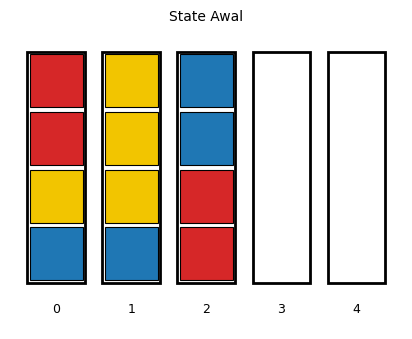

In [ ]:
# ===== Dataset: Water Sort Level 3 =====
CAPACITY = 4

LEVEL3 = (
    ("Biru",   "Kuning", "Merah", "Merah"),    # Tabung 0 (dasar -> atas)
    ("Biru",   "Kuning", "Kuning", "Kuning"),  # Tabung 1
    ("Merah",  "Merah",  "Biru",  "Biru"),     # Tabung 2
    (),                                        # Tabung 3 (kosong)
    (),                                        # Tabung 4 (kosong)
)

LEVEL3 = validate_state(LEVEL3, CAPACITY)
print("Initial state Level 3:")
for idx, tube in enumerate(LEVEL3):
    print(f"  Tabung {idx}: {list(tube)}")
print("\nh(initial) =", heuristic(LEVEL3))
show_state(LEVEL3, CAPACITY, "State Awal")

## 3.3 Pengujian Ketiga Algoritma

Sel berikut memanggil UCS, Greedy Best-First Search, dan A\* pada *initial state* Level 3 secara berurutan, lalu mencetak jalur solusi yang ditemukan oleh masing-masing algoritma.

In [ ]:
# ===== Pemanggilan & pengujian ketiga algoritma pada Level 3 =====
df_level3, results_level3 = compare_algorithms(LEVEL3, CAPACITY, n_repeat=5)

for name, res in results_level3.items():
    print("=" * 60)
    print(f"{name}  |  langkah: {len(res.path)}  |  node diekspansi: {res.expanded}  |  node dibangkitkan: {res.generated}")
    print("=" * 60)
    print("\n".join(describe_solution(res.path)))
    final_state = replay(LEVEL3, res.path, CAPACITY)[-1]
    print("Goal tercapai?", is_goal(final_state), "\n")

UCS  |  langkah: 5  |  node diekspansi: 126  |  node dibangkitkan: 199
Langkah  1: Tabung 1 -> Tabung 3  (3x Kuning)
Langkah  2: Tabung 2 -> Tabung 1  (2x Biru)
Langkah  3: Tabung 0 -> Tabung 2  (2x Merah)
Langkah  4: Tabung 0 -> Tabung 3  (1x Kuning)
Langkah  5: Tabung 0 -> Tabung 1  (1x Biru)
Goal tercapai? True 

Greedy Best-First  |  langkah: 6  |  node diekspansi: 13  |  node dibangkitkan: 27
Langkah  1: Tabung 0 -> Tabung 3  (2x Merah)
Langkah  2: Tabung 0 -> Tabung 4  (1x Kuning)
Langkah  3: Tabung 1 -> Tabung 4  (3x Kuning)
Langkah  4: Tabung 2 -> Tabung 0  (2x Biru)
Langkah  5: Tabung 0 -> Tabung 1  (3x Biru)
Langkah  6: Tabung 2 -> Tabung 3  (2x Merah)
Goal tercapai? True 

A*  |  langkah: 5  |  node diekspansi: 84  |  node dibangkitkan: 131
Langkah  1: Tabung 1 -> Tabung 3  (3x Kuning)
Langkah  2: Tabung 2 -> Tabung 1  (2x Biru)
Langkah  3: Tabung 0 -> Tabung 2  (2x Merah)
Langkah  4: Tabung 0 -> Tabung 3  (1x Kuning)
Langkah  5: Tabung 0 -> Tabung 1  (1x Biru)
Goal tercapai

## 3.4 Tabel Komparasi

Tabel berikut merangkum performa ketiga algoritma. Nilai *node diekspansi*, *node dibangkitkan*, dan *panjang solusi* bersifat deterministik, sedangkan *waktu eksekusi* dapat sedikit berbeda antar-mesin dan antar-proses.

In [ ]:
# ===== Tabel Komparasi =====
styled = (df_level3.style
          .format({"Waktu (ms)": "{:.3f}", "Node Diekspansi": "{:.0f}", "Node Dibangkitkan": "{:.0f}",
                   "Panjang Solusi": "{:.0f}", "Maks. Frontier": "{:.0f}"})
          .hide(axis="index")
          .set_caption("Tabel 3.1 — Perbandingan UCS, Greedy Best-First, dan A* pada Water Sort Level 3"))
display(styled)
print()
print_summary(df_level3)

Algoritma,Waktu (ms),Node Diekspansi,Node Dibangkitkan,Panjang Solusi,Maks. Frontier,Optimal?
UCS,2.511,126,199,5,76,Ya
Greedy Best-First,0.261,13,27,6,19,Tidak
A*,1.521,84,131,5,58,Ya



Ringkasan otomatis:
 - Waktu tercepat          : Greedy Best-First
 - Node diekspansi tersedikit: Greedy Best-First
 - Solusi terpendek        : UCS, A* (5 langkah)


## 3.5 Visualisasi Perbandingan (Chart)

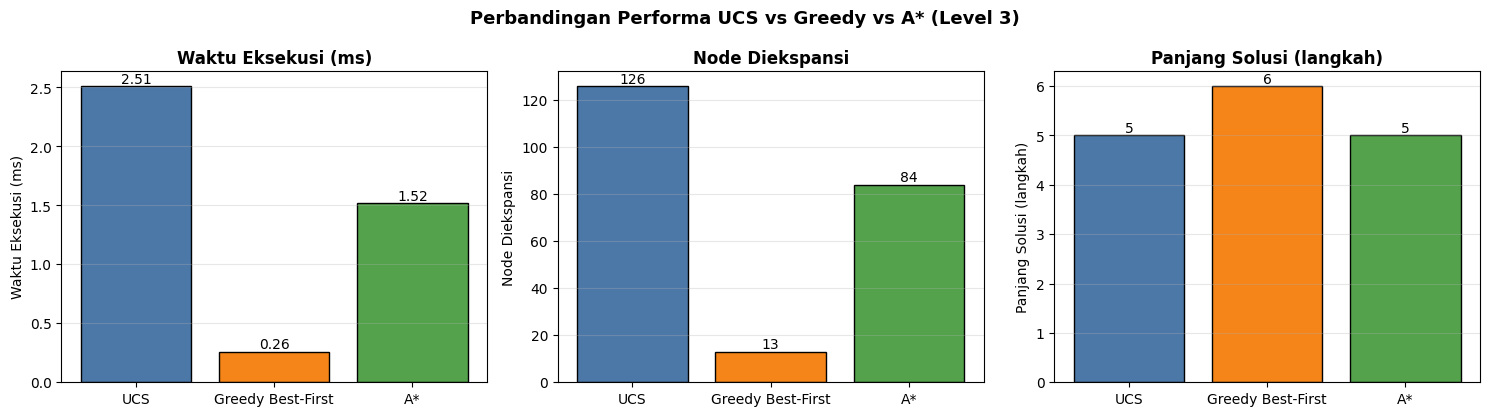

In [ ]:
# ===== Chart: Waktu Eksekusi, Node Diekspansi, Panjang Solusi =====
plot_comparison(df_level3, " (Level 3)")

## 3.6 Visualisasi Jalur Solusi Optimal (A\*)

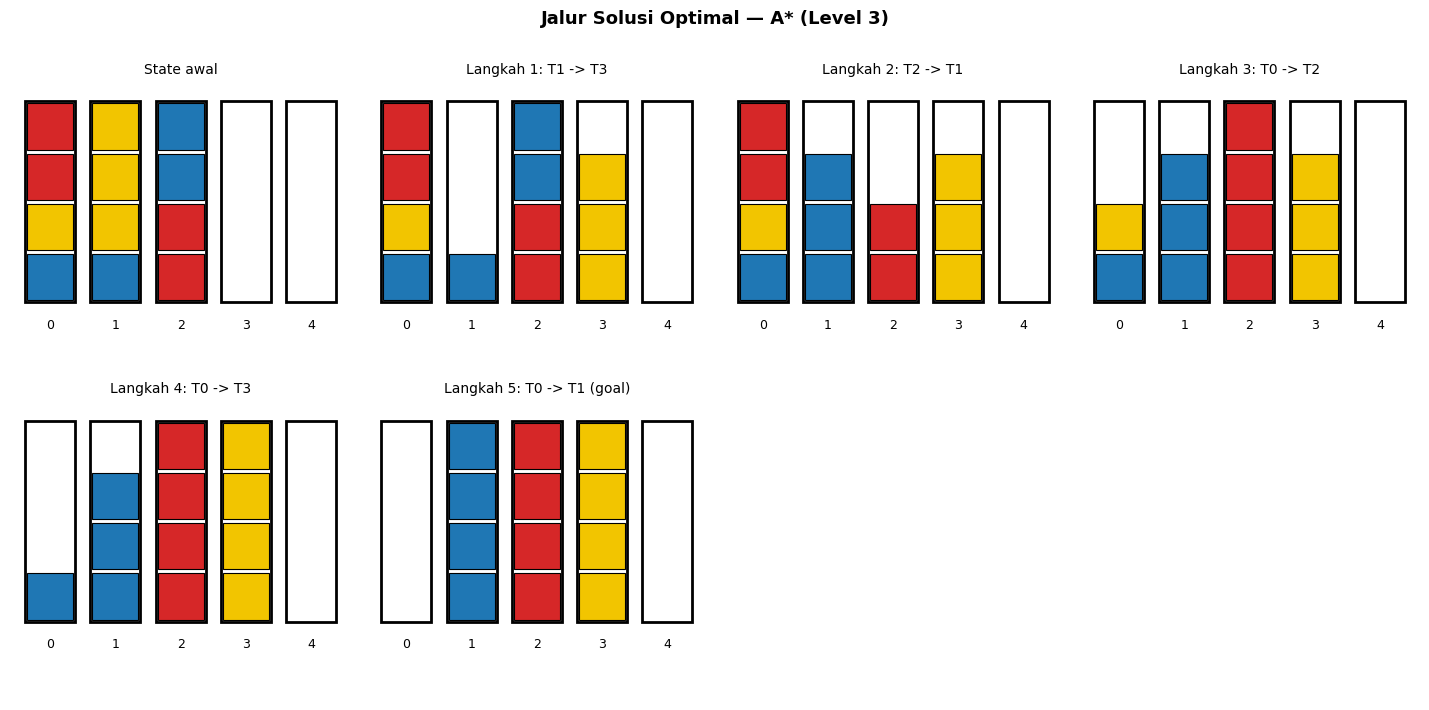

In [ ]:
# ===== Visualisasi jalur solusi A* =====
draw_solution(LEVEL3, results_level3["A*"].path, CAPACITY, "Jalur Solusi Optimal — A* (Level 3)")

## 3.7 Pembahasan Hasil Eksperimen

Hasil pengujian pada Level 3 (nilai *node* dan *panjang solusi* bersifat deterministik; waktu eksekusi bergantung pada mesin dan hanya dipakai untuk perbandingan relatif) dirangkum sebagai berikut.

| Algoritma | Node Diekspansi | Node Dibangkitkan | Panjang Solusi | Waktu (± ms) | Optimal |
|---|:---:|:---:|:---:|:---:|:---:|
| UCS | 126 | 199 | 5 | 2,7 | Ya |
| Greedy Best-First | 13 | 27 | 6 | 0,3 | Tidak |
| A\* | 84 | 131 | 5 | 1,7 | Ya |

**1. Kualitas solusi (panjang jalur).** UCS dan A\* sama-sama menemukan solusi dengan **5 langkah**, yang merupakan jumlah langkah minimum. Hasil ini sesuai dengan teori: UCS optimal karena seluruh langkah berbiaya sama, sedangkan A\* optimal karena heuristik jumlah perubahan warna bersifat *admissible* dan *consistent*. Nilai $h(\text{initial}) = 4$ juga tidak melebihi biaya optimal sebenarnya (5 langkah), sehingga konsisten dengan sifat *admissible*. Greedy Best-First menghasilkan solusi **6 langkah**, atau 1 langkah (20%) lebih panjang dari optimal. Hal ini terjadi karena Greedy hanya menilai kedekatan terhadap *goal* melalui $h(n)$ dan mengabaikan biaya yang sudah ditempuh $g(n)$; misalnya ia memilih menuang ke tabung kosong yang menurunkan $h$ secara cepat, tetapi menimbulkan langkah tambahan di tahap akhir.

**2. Efisiensi ruang pencarian (node diekspansi).** UCS mengekspansi 126 node karena menjelajahi seluruh *state* pada kedalaman 0 sampai 4 sebelum mencapai kedalaman 5, tanpa panduan arah. A\* hanya mengekspansi 84 node (sekitar **33% lebih sedikit** daripada UCS) karena heuristik mengarahkan pencarian menjauhi *state* yang masih banyak tercampur. Greedy hanya mengekspansi 13 node (sekitar **90% lebih sedikit** daripada UCS) karena pencarian langsung "menukik" ke arah nilai $h$ terendah.

**3. Waktu eksekusi.** Urutan waktu mengikuti jumlah node yang diproses: Greedy (tercepat) < A\* < UCS. Perlu dicatat bahwa A\* menghitung heuristik untuk setiap node yang dibangkitkan, namun biaya tambahan ini kecil dibandingkan penghematan ekspansi node, sehingga A\* tetap lebih cepat daripada UCS.

**4. Trade-off.** Eksperimen memperlihatkan *trade-off* klasik pada pencarian: Greedy unggul dalam kecepatan dan penggunaan memori, UCS menjamin optimalitas tetapi paling mahal secara komputasi, dan A\* memberikan **keseimbangan terbaik** karena tetap optimal dengan biaya komputasi yang lebih rendah daripada UCS.

**5. Keterbatasan.** Eksperimen utama hanya memakai satu instans (Level 3) yang ruang keadaannya kecil, sehingga selisih waktu absolut terlihat dalam orde milidetik. Pada puzzle dengan lebih banyak tabung, warna, atau kapasitas, selisih jumlah node antara UCS dan A\* diperkirakan melebar. Pembaca dapat mengujinya melalui sel konfigurasi kustom pada subbab 3.8 (contoh bawaan sel tersebut, puzzle 3 warna dengan kapasitas 4, juga menunjukkan pola yang sama: UCS dan A\* optimal sedangkan Greedy menghasilkan solusi lebih panjang).

## 3.8 Uji Coba Konfigurasi Kustom (*Custom Initial State*)

Sel kode **di bawah ini terpisah dan dapat diubah (*editable*)**. Untuk mencoba puzzle lain:

1. Ubah `CUSTOM_CAPACITY` (kapasitas tiap tabung).
2. Ubah `CUSTOM_TUBES`: tiap elemen adalah satu tabung, ditulis **dari dasar ke atas**. Gunakan `[]` untuk tabung kosong.
3. Nama warna bebas (contoh: `"Biru"`, `"Kuning"`, `"Merah"`, `"Hijau"`, `"Oranye"`, `"Ungu"`, `"Pink"`, `"Cokelat"`, `"Abu-abu"`, `"Cyan"`, `"Lime"`, `"Putih"`); nama lain akan diberi warna otomatis.
4. Jalankan sel (*Shift + Enter*); ketiga algoritma akan langsung diuji, lengkap dengan tabel, chart, dan visualisasi solusi.

> Pastikan sel-sel sebelumnya (implementasi) telah dijalankan terlebih dahulu. Jika jumlah blok per warna tidak sama dengan kapasitas, program hanya menampilkan peringatan; puzzle tetap dijalankan selama masih mungkin diselesaikan.

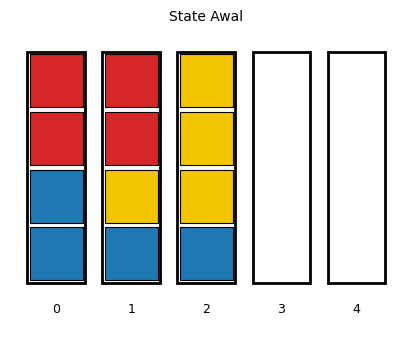

h(initial) = 4  |  jumlah tabung = 5  |  kapasitas = 4



Algoritma,Waktu (ms),Node Diekspansi,Node Dibangkitkan,Panjang Solusi,Maks. Frontier,Optimal?
UCS,2.135,105,169,6,66,Ya
Greedy Best-First,0.235,12,25,6,18,Ya
A*,2.173,90,155,6,66,Ya



Ringkasan otomatis:
 - Waktu tercepat          : Greedy Best-First
 - Node diekspansi tersedikit: Greedy Best-First
 - Solusi terpendek        : UCS, Greedy Best-First, A* (6 langkah)


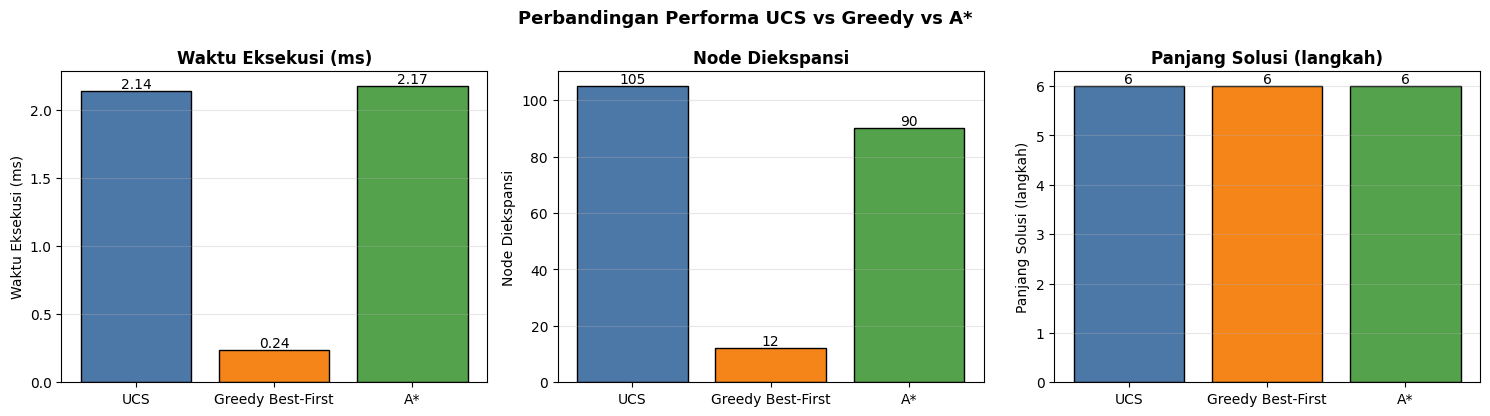


Solusi UCS (6 langkah):
  Langkah  1: Tabung 0 -> Tabung 3  (2x Merah)
  Langkah  2: Tabung 1 -> Tabung 3  (2x Merah)
  Langkah  3: Tabung 1 -> Tabung 4  (1x Kuning)
  Langkah  4: Tabung 0 -> Tabung 1  (2x Biru)
  Langkah  5: Tabung 2 -> Tabung 4  (3x Kuning)
  Langkah  6: Tabung 1 -> Tabung 2  (3x Biru)

Solusi Greedy Best-First (6 langkah):
  Langkah  1: Tabung 0 -> Tabung 3  (2x Merah)
  Langkah  2: Tabung 1 -> Tabung 3  (2x Merah)
  Langkah  3: Tabung 1 -> Tabung 4  (1x Kuning)
  Langkah  4: Tabung 2 -> Tabung 4  (3x Kuning)
  Langkah  5: Tabung 0 -> Tabung 1  (2x Biru)
  Langkah  6: Tabung 1 -> Tabung 2  (3x Biru)

Solusi A* (6 langkah):
  Langkah  1: Tabung 0 -> Tabung 3  (2x Merah)
  Langkah  2: Tabung 1 -> Tabung 3  (2x Merah)
  Langkah  3: Tabung 1 -> Tabung 4  (1x Kuning)
  Langkah  4: Tabung 2 -> Tabung 4  (3x Kuning)
  Langkah  5: Tabung 0 -> Tabung 1  (2x Biru)
  Langkah  6: Tabung 1 -> Tabung 2  (3x Biru)


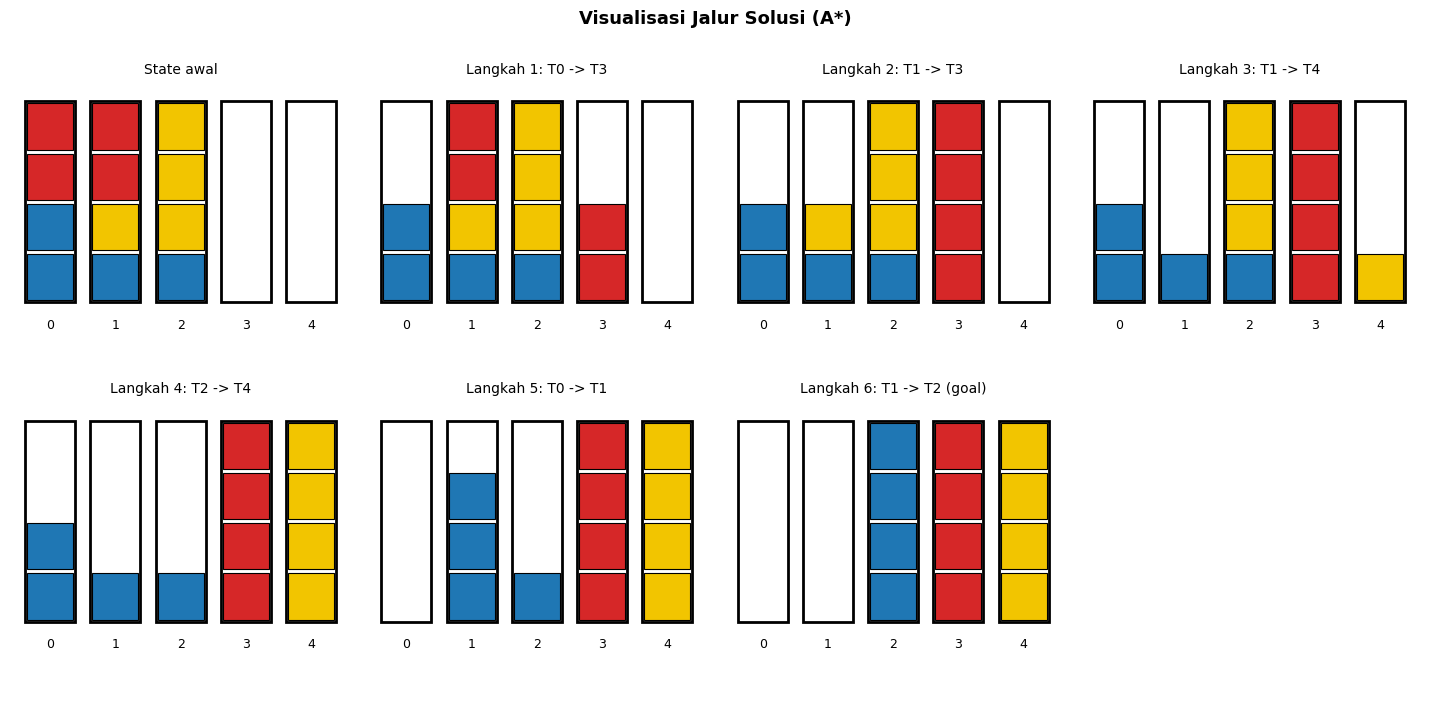

In [ ]:
# =====================================================================
#  CUSTOM INITIAL STATE  —  EDIT BAGIAN INI, LALU JALANKAN SEL
# =====================================================================
CUSTOM_CAPACITY = 4

CUSTOM_TUBES = [
    ["Biru", "Biru", "Merah", "Merah"],       # Tabung 0 (dasar -> atas)
    ["Biru", "Kuning", "Merah", "Merah"],    # Tabung 1
    ["Biru", "Kuning", "Kuning", "Kuning"],     # Tabung 2
    [],                                       # Tabung 5 (kosong)
    [],                                       # Tabung 6 (kosong)
]

N_REPEAT = 5            # jumlah pengulangan untuk rata-rata waktu eksekusi
# =====================================================================

df_custom, results_custom = run_experiment(CUSTOM_TUBES, CUSTOM_CAPACITY, n_repeat=N_REPEAT)

---
# Chapter 4 — Conclusion

## 4.1 Kesimpulan

Berdasarkan hasil perancangan dan eksperimen pada Water Sort Puzzle Level 3, diperoleh kesimpulan sebagai berikut.

1. **Pemodelan masalah.** Water Sort Puzzle dapat dimodelkan secara efektif sebagai masalah pencarian ruang keadaan dengan *state* berupa tuple dari tuple, operator `pour(i, j)` berbiaya 1, serta *goal test* berupa kondisi setiap tabung kosong atau berisi satu warna.
2. **Solusi optimal.** UCS dan A\* sama-sama menemukan solusi **optimal sepanjang 5 langkah**, sedangkan Greedy Best-First menemukan solusi **6 langkah** (tidak optimal).
3. **Efisiensi.** Ditinjau dari jumlah node yang diekspansi, Greedy (13 node) lebih hemat daripada A\* (84 node), dan A\* lebih hemat daripada UCS (126 node). Urutan waktu eksekusi mengikuti pola yang sama.
4. **Algoritma terbaik.** Jika yang dibutuhkan adalah **solusi dengan jumlah langkah minimum dengan biaya komputasi wajar, A\* Search merupakan algoritma paling optimal** pada eksperimen ini: kualitas solusinya setara UCS dengan sekitar 33% node lebih sedikit. Greedy sesuai dipilih apabila kecepatan lebih penting daripada optimalitas, sedangkan UCS cocok sebagai pembanding (*baseline*) yang menjamin optimalitas tanpa heuristik.
5. **Heuristik.** Fungsi heuristik jumlah perubahan warna per tabung terbukti sederhana, murah dihitung, dan memenuhi syarat *admissible* serta *consistent*, sehingga cukup efektif untuk memandu pencarian pada Water Sort Puzzle.

## 4.2 Saran Pengembangan

* Menguji algoritma pada puzzle yang lebih besar (lebih banyak tabung dan warna) untuk mengukur skalabilitas.
* Merancang heuristik yang lebih informatif (misalnya menambahkan penalti untuk warna yang tersebar di lebih dari satu tabung atau untuk blok yang tertimbun warna lain) dan membandingkannya dengan heuristik saat ini.
* Menambahkan algoritma lain seperti IDA\*, Weighted A\*, atau *Breadth-First Search* sebagai pembanding, serta kanonisasi *state* (menggabungkan tabung kosong yang ekuivalen) untuk mengurangi simetri ruang keadaan.

---
# References

1. Russell, S. J., & Norvig, P. (2020). *Artificial Intelligence: A Modern Approach* (4th ed.). Pearson. — Bab 3 (*Solving Problems by Searching*) dan Bab 4 (*Search in Complex Environments*).
2. Hart, P. E., Nilsson, N. J., & Raphael, B. (1968). A formal basis for the heuristic determination of minimum cost paths. *IEEE Transactions on Systems Science and Cybernetics, 4*(2), 100–107.
3. Dijkstra, E. W. (1959). A note on two problems in connexion with graphs. *Numerische Mathematik, 1*(1), 269–271.
4. Pearl, J. (1984). *Heuristics: Intelligent Search Strategies for Computer Problem Solving*. Addison-Wesley.
5. Python Software Foundation. (2026). *heapq — Heap queue algorithm*. Python 3 Documentation. https://docs.python.org/3/library/heapq.html
6. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
7. McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
8. *Midterm Project Guidelines — Artificial Intelligence* (dokumen panduan mata kuliah).